# Phase 7: Netflix Customer Segmentation Using Machine Learning

## 1. Introduction
Customer segmentation is the process of dividing customers into groups based on similar characteristics and behavior.

In this phase, we will use machine learning clustering techniques to identify different customer groups in the Netflix dataset.

## 2. Objectives
- Load and inspect the feature-engineered customer dataset.
- Select relevant customer behavior and subscription features.
- Prepare numerical data for clustering.
- Apply K-Means clustering.
- Identify the optimal number of customer groups.
- Analyze and visualize customer segments.
- Develop business recommendations for each segment.

## 3. Machine Learning Technique
- K-Means Clustering

## 4. Evaluation Techniques
- Elbow Method
- Silhouette Score
- Cluster Profiling and Visualization

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the feature-engineered dataset
df = pd.read_csv("/content/netflix_feature_engineered.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (8000, 36)


,customer_id,age,gender,country,acquisition_channel,customer_segment,preferred_language,plan_id,subscription_start_date,monthly_price,...,average_support_satisfaction,unique_issue_categories,feedback_count,average_feedback_rating,negative_feedback_count,positive_feedback_count,churned,has_viewing_activity,has_support_tickets,has_feedback
0,CUST000744,21.0,Female,United Kingdom,Organic Search,Individual,English,PLAN03,2019-06-03,22.99,...,3.0,0.0,1.0,3.0,0.0,0.0,0,1,0,1
1,CUST001502,31.0,Male,Canada,Referral,Family,French,PLAN01,2026-01-13,6.99,...,3.0,0.0,0.0,3.0,0.0,0.0,0,1,0,0
2,CUST005383,40.0,Male,United Kingdom,Paid Social,Student,English,PLAN01,2023-06-17,6.99,...,3.0,0.0,1.0,4.0,0.0,1.0,0,1,0,1
3,CUST004708,27.0,Male,United Kingdom,Partner Bundle (Telecom),Individual,Hindi,PLAN02,2019-03-09,15.49,...,3.0,0.0,0.0,3.0,0.0,0.0,1,1,0,0
4,CUST005877,36.0,Male,Indonesia,Email Campaign,Student,French,PLAN03,2025-12-03,22.99,...,3.0,0.0,0.0,3.0,0.0,0.0,0,1,0,0


In [ ]:
# Select relevant numerical features for customer segmentation

segmentation_features = [
    "age",
    "monthly_price",
    "subscription_tenure_days",
    "payment_count",
    "failed_payment_count",
    "average_payment_amount",
    "total_payment_amount",
    "payment_failure_rate",
    "viewing_sessions",
    "total_watch_minutes",
    "average_watch_minutes",
    "average_completion_percentage",
    "average_session_duration",
    "unique_content_watched",
    "unique_devices_used",
    "support_ticket_count",
    "average_resolution_hours",
    "average_support_satisfaction",
    "unique_issue_categories",
    "feedback_count",
    "average_feedback_rating",
    "negative_feedback_count",
    "positive_feedback_count",
    "has_viewing_activity",
    "has_support_tickets",
    "has_feedback"
]

# Create the segmentation dataset
X_seg = df[segmentation_features].copy()

print("Segmentation features selected successfully!")
print("Number of features:", len(segmentation_features))
print("Segmentation dataset shape:", X_seg.shape)

display(X_seg.head())

Segmentation features selected successfully!
Number of features: 26
Segmentation dataset shape: (8000, 26)


,age,monthly_price,subscription_tenure_days,payment_count,failed_payment_count,average_payment_amount,total_payment_amount,payment_failure_rate,viewing_sessions,total_watch_minutes,...,average_resolution_hours,average_support_satisfaction,unique_issue_categories,feedback_count,average_feedback_rating,negative_feedback_count,positive_feedback_count,has_viewing_activity,has_support_tickets,has_feedback
0,21.0,22.99,2584,15,2,22.990000,344.85,0.133333,5.0,266.0,...,13.4,3.0,0.0,1.0,3.0,0.0,0.0,1,0,1
1,31.0,6.99,168,5,0,6.990000,34.95,0.000000,5.0,309.0,...,13.4,3.0,0.0,0.0,3.0,0.0,0.0,1,0,0
2,40.0,6.99,1109,15,1,6.524000,97.86,0.066667,6.0,301.0,...,13.4,3.0,0.0,1.0,4.0,0.0,1.0,1,0,1
3,27.0,15.49,2497,15,1,15.490000,232.35,0.066667,10.0,389.0,...,13.4,3.0,0.0,0.0,3.0,0.0,0.0,1,0,0
4,36.0,22.99,209,6,1,19.158333,114.95,0.166667,5.0,286.0,...,13.4,3.0,0.0,0.0,3.0,0.0,0.0,1,0,0


In [ ]:
# Check missing values
print("Missing values in each feature:")
display(X_seg.isnull().sum())

# Check total missing values
print("\nTotal missing values:", X_seg.isnull().sum().sum())

# Check duplicate rows
print("Duplicate rows:", X_seg.duplicated().sum())

# Check dataset information
print("\nDataset information:")
print(X_seg.info())

Missing values in each feature:


,0
age,0
monthly_price,0
subscription_tenure_days,0
payment_count,0
failed_payment_count,0
average_payment_amount,0
total_payment_amount,0
payment_failure_rate,0
viewing_sessions,0
total_watch_minutes,0



Total missing values: 0
Duplicate rows: 0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 26 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   age                            8000 non-null   float64
 1   monthly_price                  8000 non-null   float64
 2   subscription_tenure_days       8000 non-null   int64  
 3   payment_count                  8000 non-null   int64  
 4   failed_payment_count           8000 non-null   int64  
 5   average_payment_amount         8000 non-null   float64
 6   total_payment_amount           8000 non-null   float64
 7   payment_failure_rate           8000 non-null   float64
 8   viewing_sessions               8000 non-null   float64
 9   total_watch_minutes            8000 non-null   float64
 10  average_watch_minutes          8000 non-null   float64
 11  average_completion_percentage  8000 non-nul

In [ ]:
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Scale the segmentation features
X_scaled = scaler.fit_transform(X_seg)

# Convert scaled data into a DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=segmentation_features
)

print("Feature scaling completed successfully!")
print("Scaled dataset shape:", X_scaled_df.shape)

display(X_scaled_df.head())

# Check scaled feature statistics
print("\nMean of scaled features:")
print(X_scaled_df.mean().round(2).head())

print("\nStandard deviation of scaled features:")
print(X_scaled_df.std().round(2).head())

Feature scaling completed successfully!
Scaled dataset shape: (8000, 26)


,age,monthly_price,subscription_tenure_days,payment_count,failed_payment_count,average_payment_amount,total_payment_amount,payment_failure_rate,viewing_sessions,total_watch_minutes,...,average_resolution_hours,average_support_satisfaction,unique_issue_categories,feedback_count,average_feedback_rating,negative_feedback_count,positive_feedback_count,has_viewing_activity,has_support_tickets,has_feedback
0,-1.095153,1.562021,1.664917,0.387654,1.090657,1.400947,1.510241,0.794280,-0.695276,-0.510975,...,-0.175115,-0.157415,-0.883508,0.468956,-0.101026,-0.392205,-0.468974,0.139169,-1.058987,1.151339
1,-0.145540,-1.050771,-1.394475,-2.602924,-0.874712,-1.022805,-1.481911,-0.773771,-0.695276,-0.310952,...,-0.175115,-0.157415,-0.883508,-0.713410,-0.101026,-0.392205,-0.468974,0.139169,-1.058987,-0.868554
2,0.709112,-1.050771,-0.202882,0.387654,0.107972,-1.093397,-0.874502,0.010255,-0.428619,-0.348166,...,-0.175115,-0.157415,-0.883508,0.468956,1.166892,-0.392205,1.491210,0.139169,-1.058987,1.151339
3,-0.525385,0.337275,1.554749,0.387654,0.107972,0.264813,0.424029,0.010255,0.638011,0.061183,...,-0.175115,-0.157415,-0.883508,-0.713410,-0.101026,-0.392205,-0.468974,0.139169,-1.058987,-0.868554
4,0.329266,1.562021,-1.342557,-2.303866,0.107972,0.820509,-0.709494,1.186292,-0.695276,-0.417941,...,-0.175115,-0.157415,-0.883508,-0.713410,-0.101026,-0.392205,-0.468974,0.139169,-1.058987,-0.868554



Mean of scaled features:
age                        -0.0
monthly_price              -0.0
subscription_tenure_days    0.0
payment_count               0.0
failed_payment_count       -0.0
dtype: float64

Standard deviation of scaled features:
age                         1.0
monthly_price               1.0
subscription_tenure_days    1.0
payment_count               1.0
failed_payment_count        1.0
dtype: float64


## 5. Feature Scaling

### Objective
To bring all numerical features to a comparable scale before applying K-Means clustering.

### Method
StandardScaler was used to transform the numerical features so that they have approximately zero mean and unit standard deviation.

### Why Scaling Is Important
K-Means uses distances to group similar customers. Scaling prevents features with larger numerical ranges from dominating the clustering process.

### Conclusion
All 26 selected features were standardized before applying the clustering algorithm.

Clusters: 2, Inertia: 189490.91
Clusters: 3, Inertia: 175827.04
Clusters: 4, Inertia: 165472.00
Clusters: 5, Inertia: 157043.11
Clusters: 6, Inertia: 149171.79
Clusters: 7, Inertia: 142964.42
Clusters: 8, Inertia: 136630.51
Clusters: 9, Inertia: 131586.18
Clusters: 10, Inertia: 127570.32


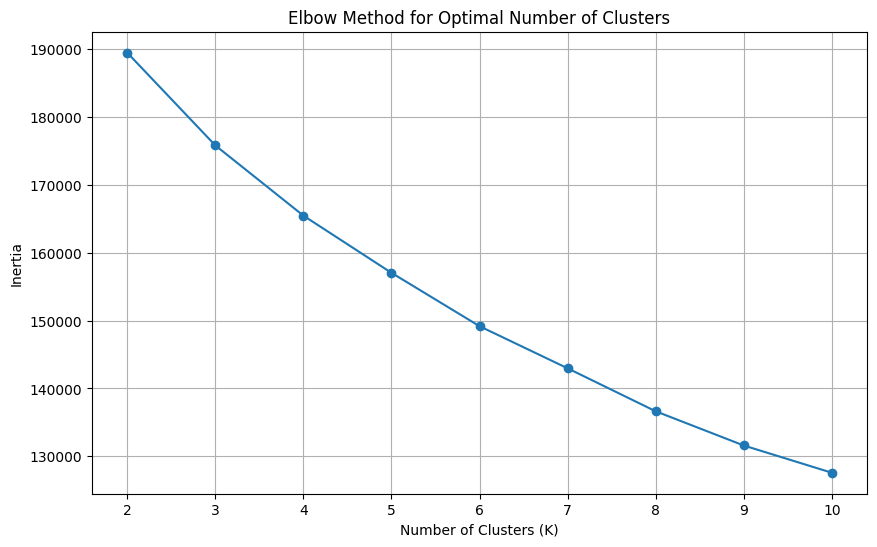

In [ ]:
from sklearn.cluster import KMeans

# Store inertia values
inertia_values = []
k_values = range(2, 11)

# Train K-Means for different cluster numbers
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

    print(f"Clusters: {k}, Inertia: {kmeans.inertia_:.2f}")

# Plot the Elbow Method graph
plt.figure(figsize=(10, 6))
plt.plot(k_values, inertia_values, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)
plt.show()

Clusters: 2, Silhouette Score: 0.0948
Clusters: 3, Silhouette Score: 0.0913
Clusters: 4, Silhouette Score: 0.0907
Clusters: 5, Silhouette Score: 0.0888
Clusters: 6, Silhouette Score: 0.0995


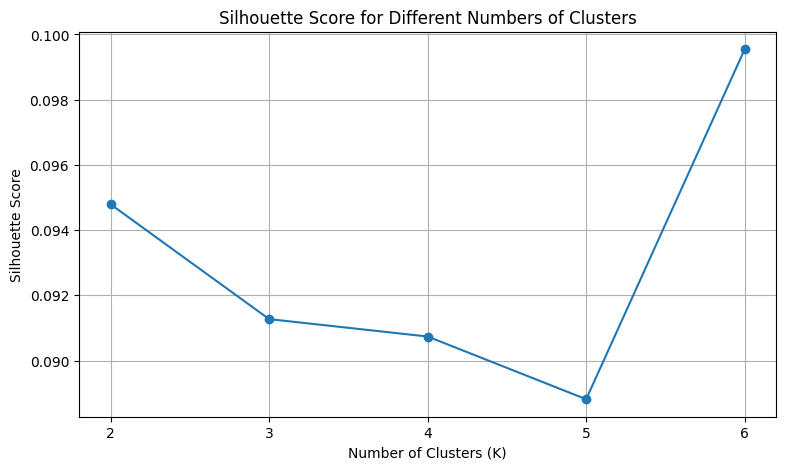

In [ ]:
from sklearn.metrics import silhouette_score

silhouette_scores = []
k_values_silhouette = range(2, 7)

for k in k_values_silhouette:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        cluster_labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

# Plot silhouette scores
plt.figure(figsize=(9, 5))
plt.plot(k_values_silhouette, silhouette_scores, marker="o")
plt.title("Silhouette Score for Different Numbers of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values_silhouette))
plt.grid(True)
plt.show()

## 7. Determining the Optimal Number of Clusters

### Objective
To identify a suitable number of customer groups for the K-Means clustering algorithm.

### Methodology
Two evaluation techniques were used:
- **Elbow Method:** Examined how inertia changes as the number of clusters increases.
- **Silhouette Score:** Compared how well-separated the resulting clusters are.

### Key Findings
- The Elbow Method showed a gradual decrease in inertia, without a sharp elbow.
- K=6 achieved the highest Silhouette Score of 0.0995 among the tested values (K=2 to K=6).
- All Silhouette Scores were low, indicating overlapping customer groups.

### Conclusion
K=6 was selected as the initial clustering candidate based on the highest Silhouette Score. Cluster sizes and customer profiles will be examined before finalizing the segmentation.

In [ ]:
# Create the final K-Means model
optimal_k = 6

kmeans_final = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Fit the model and assign cluster labels
cluster_labels = kmeans_final.fit_predict(X_scaled)

# Add cluster labels to the original dataset
df["cluster"] = cluster_labels

print("K-Means clustering completed successfully!")
print("Number of clusters:", optimal_k)

# Display customer count in each cluster
cluster_counts = df["cluster"].value_counts().sort_index()

print("\nCustomers in each cluster:")
display(cluster_counts.to_frame(name="Customer Count"))

print("\nCluster percentages:")
display(
    (cluster_counts / len(df) * 100)
    .round(2)
    .to_frame(name="Percentage")
)

K-Means clustering completed successfully!
Number of clusters: 6

Customers in each cluster:


,Customer Count
cluster,
0,2171
1,1457
2,152
3,1323
4,1878
5,1019



Cluster percentages:


,Percentage
cluster,
0,27.14
1,18.21
2,1.90
3,16.54
4,23.48
5,12.74


## 8. K-Means Clustering and Cluster Distribution

### Objective
To group Netflix customers into six clusters based on their selected behavioral, subscription, payment, and support features.

### Methodology
The K-Means algorithm was trained using the standardized dataset with six clusters. A fixed random state of 42 was used to make the results reproducible.

### Key Findings
- Total customers grouped: 8,000
- Number of clusters: 6
- Largest cluster: Cluster 0 (2,171 customers, 27.14%)
- Second-largest cluster: Cluster 4 (1,878 customers, 23.48%)
- Smallest cluster: Cluster 2 (152 customers, 1.90%)

### Interpretation
The customer distribution is uneven. Cluster 2 contains a relatively small group and may represent customers with unusual or distinct characteristics.

### Conclusion
Six customer groups were generated successfully. Further cluster profiling is required to understand their characteristics and determine whether the selected clustering structure is meaningful.

In [ ]:
# Calculate average feature values for each cluster
cluster_profile = df.groupby("cluster")[segmentation_features].mean()

print("Customer Cluster Profiles:")
display(cluster_profile.round(2))

Customer Cluster Profiles:


,age,monthly_price,subscription_tenure_days,payment_count,failed_payment_count,average_payment_amount,total_payment_amount,payment_failure_rate,viewing_sessions,total_watch_minutes,...,average_resolution_hours,average_support_satisfaction,unique_issue_categories,feedback_count,average_feedback_rating,negative_feedback_count,positive_feedback_count,has_viewing_activity,has_support_tickets,has_feedback
cluster,,,,,,,,,,,,,,,,,,,,,
0,32.56,13.23,1305.40,13.94,0.97,13.50,188.26,0.07,9.29,461.67,...,17.12,3.26,1.35,0.18,3.00,0.01,0.01,1.0,1.00,0.16
1,32.69,13.86,1093.43,12.99,0.76,14.23,185.79,0.06,2.88,132.62,...,15.29,3.02,0.58,0.30,3.07,0.04,0.08,1.0,0.50,0.27
2,33.64,13.72,953.09,11.80,0.72,13.73,161.28,0.06,0.00,0.00,...,16.49,2.95,0.49,0.38,3.09,0.09,0.18,0.0,0.40,0.30
3,32.47,13.42,1328.35,13.80,0.76,13.67,189.18,0.05,8.56,420.71,...,15.04,3.14,0.65,1.49,4.28,0.07,1.17,1.0,0.54,1.00
4,32.09,13.43,1329.95,13.85,0.88,13.80,191.15,0.06,9.13,452.43,...,13.40,3.00,0.00,0.18,3.00,0.00,0.00,1.0,0.00,0.17
5,32.99,13.19,1301.93,14.10,1.10,13.53,190.65,0.08,7.87,397.44,...,15.69,3.10,0.70,1.59,1.86,1.16,0.18,1.0,0.54,1.00


## 9. Customer Cluster Profiling

### Objective
To understand the characteristics and behavior of customers in each K-Means cluster.

### Methodology
Customers were grouped by their cluster labels, and the average values of the 26 selected features were calculated for each group.

### Key Findings
- Cluster 0 showed high viewing activity and a relatively high number of support tickets.
- Cluster 1 showed comparatively low viewing activity.
- Cluster 2 had no recorded viewing activity and was the smallest cluster.
- Cluster 3 had high viewing activity and the highest average feedback rating of 4.28.
- Cluster 4 had high viewing activity and no recorded support tickets.
- Cluster 5 had the lowest average feedback rating of 1.86 and a relatively high number of negative feedback records.

### Interpretation
The clusters show differences in customer engagement, feedback, and support interactions. These differences can help identify customer groups with different service experiences and engagement patterns.

### Conclusion
Cluster profiling provides an initial understanding of Netflix customer behavior. Further analysis and visualization are required before assigning final business labels to the customer groups.

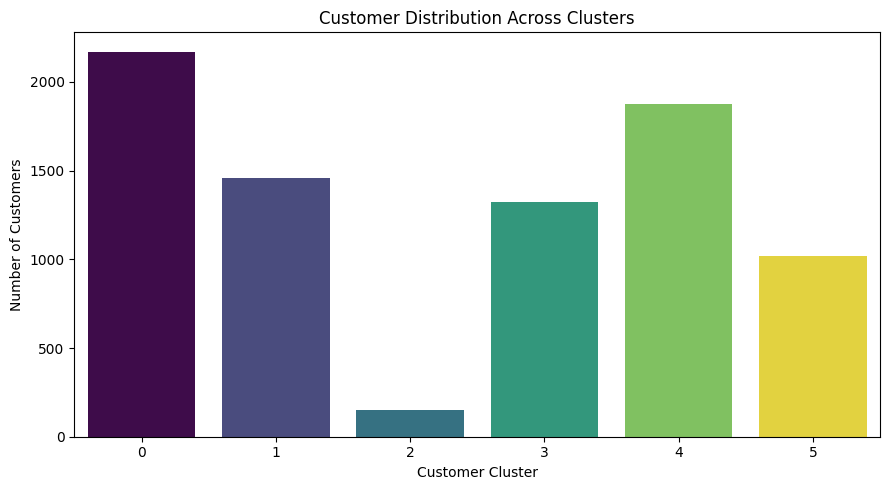

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="cluster",
    hue="cluster",
    palette="viridis",
    legend=False
)

plt.title("Customer Distribution Across Clusters")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## 10. Customer Cluster Distribution Visualization

### Objective
To visualize the number of customers assigned to each cluster.

### Methodology
A bar chart was created using Seaborn to compare the customer count across all six clusters.

### Key Findings
- Cluster 0 contains the highest number of customers (2,171).
- Cluster 4 contains 1,878 customers.
- Cluster 2 contains the fewest customers (152).
- The remaining clusters contain between 1,019 and 1,457 customers.

### Interpretation
The chart shows an uneven distribution of customers across the six groups. Cluster 2 is particularly small compared with the other clusters.

### Conclusion
The visualization provides a clear comparison of customer group sizes and helps identify clusters that require further investigation.

In [ ]:
# Calculate churn rate for each cluster
cluster_churn = df.groupby("cluster").agg(
    Total_Customers=("customer_id", "count"),
    Churned_Customers=("churned", "sum"),
    Churn_Rate=("churned", "mean")
)

cluster_churn["Churn_Rate"] = (
    cluster_churn["Churn_Rate"] * 100
).round(2)

print("Churn Analysis Across Customer Clusters:")
display(cluster_churn)

Churn Analysis Across Customer Clusters:


,Total_Customers,Churned_Customers,Churn_Rate
cluster,,,
0,2171,333,15.34
1,1457,730,50.10
2,152,141,92.76
3,1323,203,15.34
4,1878,323,17.20
5,1019,261,25.61


## 11. Churn Analysis Across Customer Clusters

### Objective
To compare historical customer churn rates across the six identified customer groups.

### Methodology
The dataset was grouped by cluster, and the total customers, churned customers, and average churn rate were calculated for each group.

### Key Findings
- Cluster 2 recorded the highest churn rate of 92.76% (141 out of 152 customers).
- Cluster 1 had a churn rate of 50.10%.
- Cluster 5 had a churn rate of 25.61%.
- Cluster 0 and Cluster 3 had the lowest churn rates at 15.34%.
- Cluster 4 had a churn rate of 17.20%.

### Interpretation
Cluster 2 and Cluster 1 represent groups requiring further investigation for customer retention. Cluster 2 is particularly interesting because its customers had no recorded viewing activity.

### Conclusion
Historical churn analysis reveals significant differences between customer groups. These findings can help prioritize customer retention analysis. The results describe historical associations and do not establish future churn predictions.

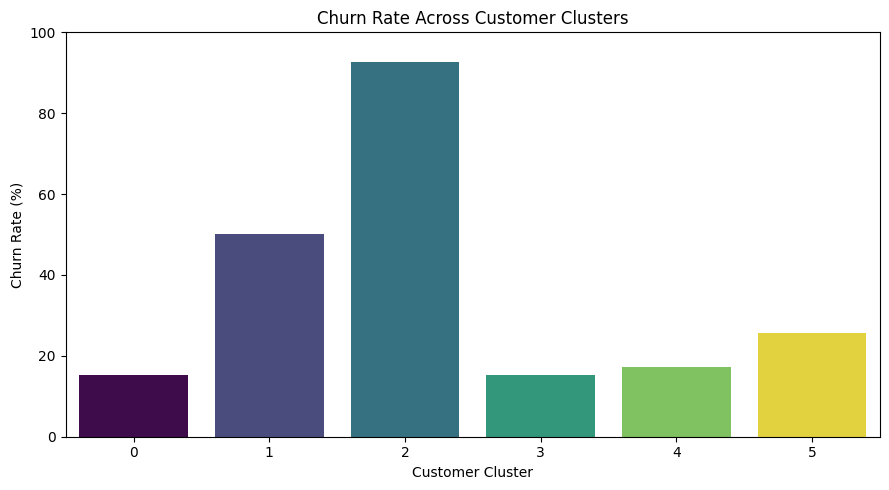

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=cluster_churn.index,
    y=cluster_churn["Churn_Rate"],
    hue=cluster_churn.index,
    palette="viridis",
    legend=False
)

plt.title("Churn Rate Across Customer Clusters")
plt.xlabel("Customer Cluster")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 12. Churn Rate Visualization Across Customer Clusters

### Objective
To visually compare historical churn rates across the six customer segments.

### Methodology
A bar chart was created using Seaborn to display the churn percentage for each cluster.

### Key Findings
- Cluster 2 recorded the highest churn rate at 92.76%.
- Cluster 1 recorded a churn rate of 50.10%.
- Cluster 5 recorded a churn rate of 25.61%.
- Clusters 0 and 3 recorded the lowest churn rates at 15.34%.

### Interpretation
The visualization highlights significant differences in historical churn behavior. Cluster 2 and Cluster 1 deserve further investigation for customer retention strategies.

### Conclusion
The chart makes it easier to identify customer groups with higher historical churn rates and supports data-driven retention analysis.

In [ ]:
# Calculate average viewing activity by cluster
engagement_profile = df.groupby("cluster").agg(
    Average_Viewing_Sessions=("viewing_sessions", "mean"),
    Average_Watch_Minutes=("total_watch_minutes", "mean")
).round(2)

print("Customer Engagement Across Clusters:")
display(engagement_profile)

Customer Engagement Across Clusters:


,Average_Viewing_Sessions,Average_Watch_Minutes
cluster,,
0,9.29,461.67
1,2.88,132.62
2,0.00,0.00
3,8.56,420.71
4,9.13,452.43
5,7.87,397.44


## 13. Customer Engagement Analysis Across Clusters

### Objective
To compare customer viewing activity across the six identified customer groups.

### Methodology
Average viewing sessions and total watch minutes were calculated for each cluster.

### Key Findings
- Cluster 0 had the highest average viewing sessions (9.29) and watch time (461.67 minutes).
- Cluster 4 also showed high engagement, with 9.13 sessions and 452.43 watch minutes.
- Cluster 3 recorded 8.56 sessions and 420.71 watch minutes.
- Cluster 1 showed low engagement, with 2.88 sessions and 132.62 watch minutes.
- Cluster 2 had no recorded viewing activity.
- Cluster 5 recorded 7.87 sessions and 397.44 watch minutes.

### Interpretation
Clusters 0, 3, and 4 show high engagement, while Clusters 1 and 2 show low or no recorded activity. Cluster 5 demonstrates that relatively high engagement does not always mean low churn.

### Conclusion
Customer engagement differs across clusters and provides useful information for understanding customer behavior and planning retention strategies.

<Figure size 1000x600 with 0 Axes>

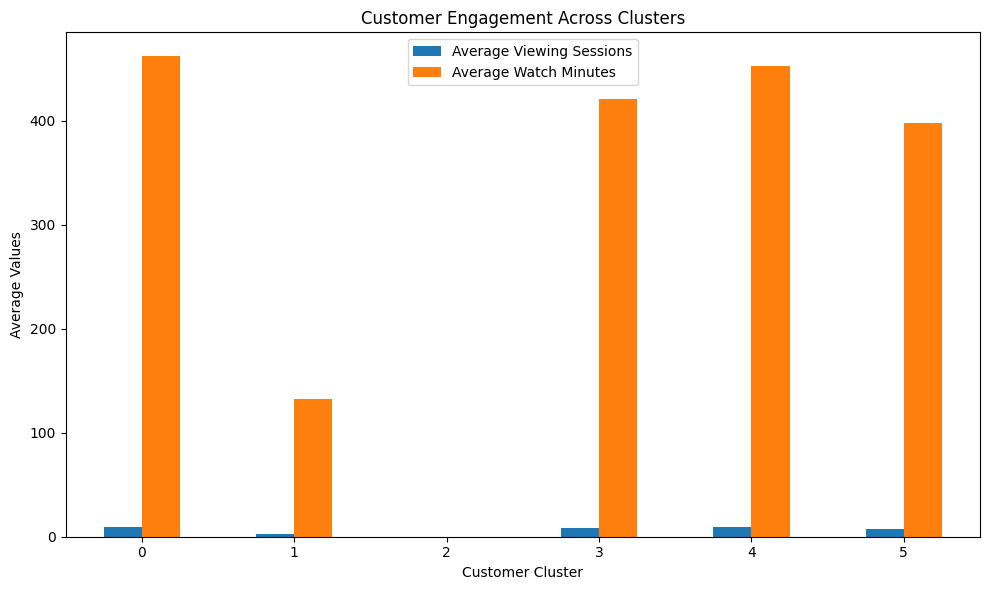

In [ ]:
plt.figure(figsize=(10, 6))

engagement_profile[
    ["Average_Viewing_Sessions", "Average_Watch_Minutes"]
].plot(kind="bar", figsize=(10, 6))

plt.title("Customer Engagement Across Clusters")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Values")
plt.xticks(rotation=0)
plt.legend(["Average Viewing Sessions", "Average Watch Minutes"])
plt.tight_layout()
plt.show()

## 14. Customer Engagement Visualization

### Objective
To visually compare average viewing sessions and watch time across customer clusters.

### Methodology
A grouped bar chart was created to compare the average viewing sessions and average watch minutes for each cluster.

### Key Findings
- Cluster 0 and Cluster 4 show the highest customer engagement.
- Cluster 3 also has high viewing activity.
- Cluster 1 has considerably lower engagement.
- Cluster 2 has no recorded viewing activity.
- Cluster 5 shows moderate-to-high engagement.

### Interpretation
The chart shows that customer engagement varies across segments. Clusters with lower viewing activity may need further investigation as part of customer retention analysis.

### Conclusion
Visualizing engagement helps compare customer behavior and supports the identification of less-engaged customer groups.

In [ ]:
# Add cluster labels to the original customer dataset
df["cluster"] = kmeans.labels_

# Save customer segmentation results
df.to_csv("/content/netflix_customer_segments.csv", index=False)

print("Customer segmentation results saved successfully!")
print("Saved location: /content/netflix_customer_segments.csv")
print("Dataset shape:", df.shape)

Customer segmentation results saved successfully!
Saved location: /content/netflix_customer_segments.csv
Dataset shape: (8000, 37)


## 15. Exporting Customer Segmentation Results

### Objective
To save the customer segmentation results for future analysis and dashboard integration.

### Methodology
The K-Means cluster labels were added to the original customer dataset. The updated dataset was exported as a CSV file.

### Output
- File name: `netflix_customer_segments.csv`
- Total customers: 8,000
- Total columns: 37
- Number of clusters: 6

### Conclusion
The segmentation results have been successfully exported and can be reused for customer profiling, churn analysis, dashboard development, and business recommendations.

In [ ]:
# Create a final customer segment summary
final_cluster_summary = df.groupby("cluster").agg(
    Customer_Count=("customer_id", "count"),
    Average_Age=("age", "mean"),
    Average_Monthly_Price=("monthly_price", "mean"),
    Average_Watch_Minutes=("total_watch_minutes", "mean"),
    Average_Viewing_Sessions=("viewing_sessions", "mean"),
    Churned_Customers=("churned", "sum")
).round(2)

final_cluster_summary["Churn_Rate_Percentage"] = (
    final_cluster_summary["Churned_Customers"] /
    final_cluster_summary["Customer_Count"] * 100
).round(2)

display(final_cluster_summary)

,Customer_Count,Average_Age,Average_Monthly_Price,Average_Watch_Minutes,Average_Viewing_Sessions,Churned_Customers,Churn_Rate_Percentage
cluster,,,,,,,
0,2171,32.56,13.23,461.67,9.29,333,15.34
1,1457,32.69,13.86,132.62,2.88,730,50.10
2,152,33.64,13.72,0.00,0.00,141,92.76
3,1323,32.47,13.42,420.71,8.56,203,15.34
4,1878,32.09,13.43,452.43,9.13,323,17.20
5,1019,32.99,13.19,397.44,7.87,261,25.61


## 16. Final Customer Segmentation Summary

### Objective
To summarize the six customer segments based on their customer characteristics, engagement, and historical churn behavior.

### Key Findings
- **Cluster 0:** 2,171 customers with high engagement and a 15.34% churn rate.
- **Cluster 1:** 1,457 customers with low engagement and a 50.10% churn rate.
- **Cluster 2:** 152 customers with no recorded viewing activity and a 92.76% churn rate.
- **Cluster 3:** 1,323 customers with high engagement and a 15.34% churn rate.
- **Cluster 4:** 1,878 customers with high engagement and a 17.20% churn rate.
- **Cluster 5:** 1,019 customers with moderate-to-high engagement and a 25.61% churn rate.

### Business Recommendations
1. Investigate Clusters 1 and 2 to understand their low engagement and high churn.
2. Contact inactive customers and identify possible reasons for their lack of viewing activity.
3. Maintain engagement among Clusters 0, 3, and 4 through relevant content recommendations.
4. Monitor Cluster 5 for possible changes in engagement and churn behavior.
5. Review customer feedback, payment issues, and support experiences before designing retention campaigns.

### Limitations
- Cluster 2 contains only 152 customers, so its 92.76% churn rate should be interpreted with caution.
- The cluster numbers are algorithm-generated labels, not rankings.
- These findings describe historical patterns and do not prove that any particular behavior causes churn.

### Conclusion
K-Means clustering identified six customer groups with different engagement patterns and historical churn rates. These segments can help Netflix understand customer behavior and develop more targeted retention strategies.

In [16]:
# Save the customer segmentation results
df.to_csv('/content/netflix_customer_segments.csv', index=False)

print("File saved successfully!")
print("Shape:", df.shape)

File saved successfully!
Shape: (8000, 37)


In [17]:
from google.colab import files
files.download('/content/netflix_customer_segments.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>